### 0. Import required libraries

In [31]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

### 1. Import un-sampled dataset

In [32]:
dataset_path = 'US_Accidents_March23_sampled_500k.csv'
df = pd.read_csv(dataset_path)

### 2. Get a brief overview of the data

In [33]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     500000 non-null  str    
 1   Source                 500000 non-null  str    
 2   Severity               500000 non-null  int64  
 3   Start_Time             500000 non-null  str    
 4   End_Time               500000 non-null  str    
 5   Start_Lat              500000 non-null  float64
 6   Start_Lng              500000 non-null  float64
 7   End_Lat                279623 non-null  float64
 8   End_Lng                279623 non-null  float64
 9   Distance(mi)           500000 non-null  float64
 10  Description            499999 non-null  str    
 11  Street                 499309 non-null  str    
 12  City                   499981 non-null  str    
 13  County                 500000 non-null  str    
 14  State                  500000 non-null  str    

### 3. Data Transformation

In [34]:
# Convert the String timestamps into pandas datetime objects
df['Start_Time'] = pd.to_datetime(df['Start_Time'], format='mixed', errors='coerce')
df['End_Time'] = pd.to_datetime(df['End_Time'], format='mixed', errors='coerce')

# Create new features using the datetime objects
df['Hour'] = df['Start_Time'].dt.hour
df['DayOfWeek'] = df['Start_Time'].dt.dayofweek
df['Month'] = df['Start_Time'].dt.month
df['Duration_min'] = (df['End_Time'] - df['Start_Time']).dt.total_seconds() / 60

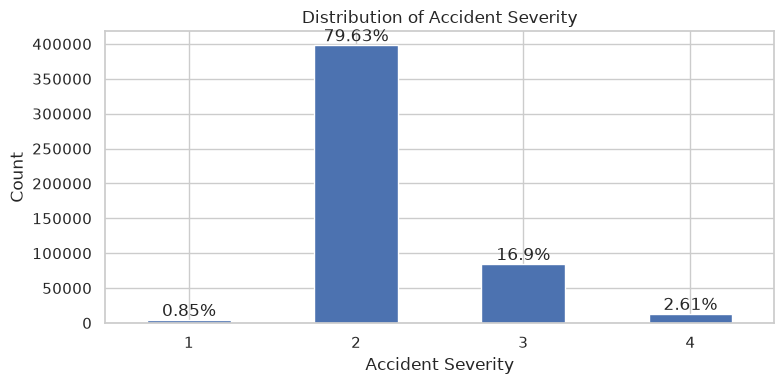

In [35]:
severity_counts = df['Severity'].value_counts().sort_index()
severity_pct = (severity_counts / len(df) * 100).round(2)
ax = severity_counts.plot(kind='bar', figsize=(8, 4), rot=0)
ax.set_xlabel('Accident Severity')
ax.set_ylabel('Count')
ax.set_title('Distribution of Accident Severity')
for i, (cnt, pct) in enumerate(zip(severity_counts, severity_pct)):
    ax.text(i, cnt, f'{pct}%', ha='center', va='bottom')
plt.tight_layout()
plt.show()

As mentioned in our proposal, severity is heavily imbalanced, with severity 2 making up roughly 80% of the records. 

In [36]:
missing = df.isna().sum()
missing = pd.DataFrame({
    'missing': missing,
    'percent': (missing / len(df) * 100).round(2)
})
missing = missing[missing['missing'] > 0].sort_values('percent', ascending=False)
missing

,missing,percent
End_Lat,220377,44.08
End_Lng,220377,44.08
Precipitation(in),142616,28.52
Wind_Chill(F),129017,25.80
Wind_Speed(mph),36987,7.40
Visibility(mi),11291,2.26
Wind_Direction,11197,2.24
Humidity(%),11130,2.23
Weather_Condition,11101,2.22
Temperature(F),10466,2.09


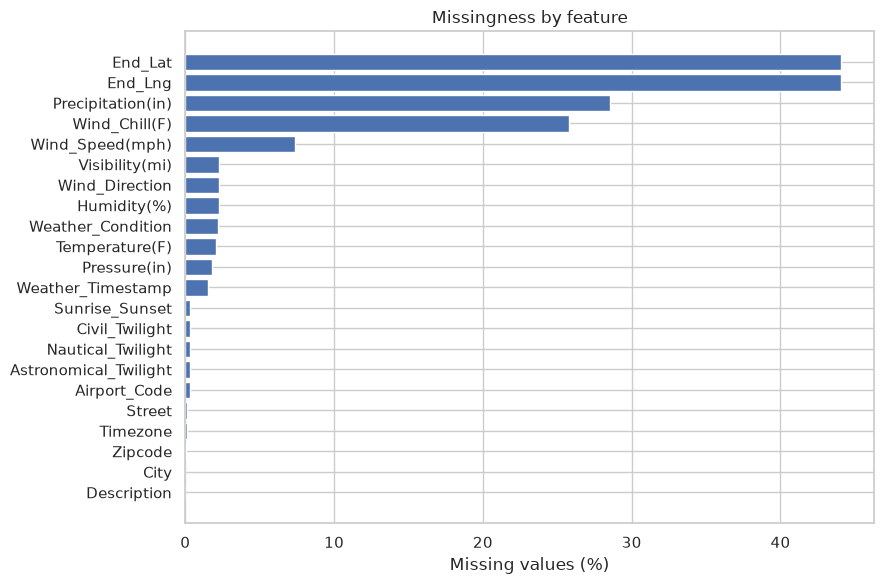

In [37]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(missing.index[::-1], missing['percent'][::-1])
ax.set_xlabel('Missing values (%)')
ax.set_title('Missingness by feature')
plt.tight_layout()
plt.show()

22 of the columns have missing values. `End_Lat` and `End_Lng` are the worst, missing in about 44% of records. `Precipitation(in)` (28.5%) and `Wind_Chill(F)` (25.8%) are the next most incomplete. The other weather features are missing in only about 2 to 7% of records. 

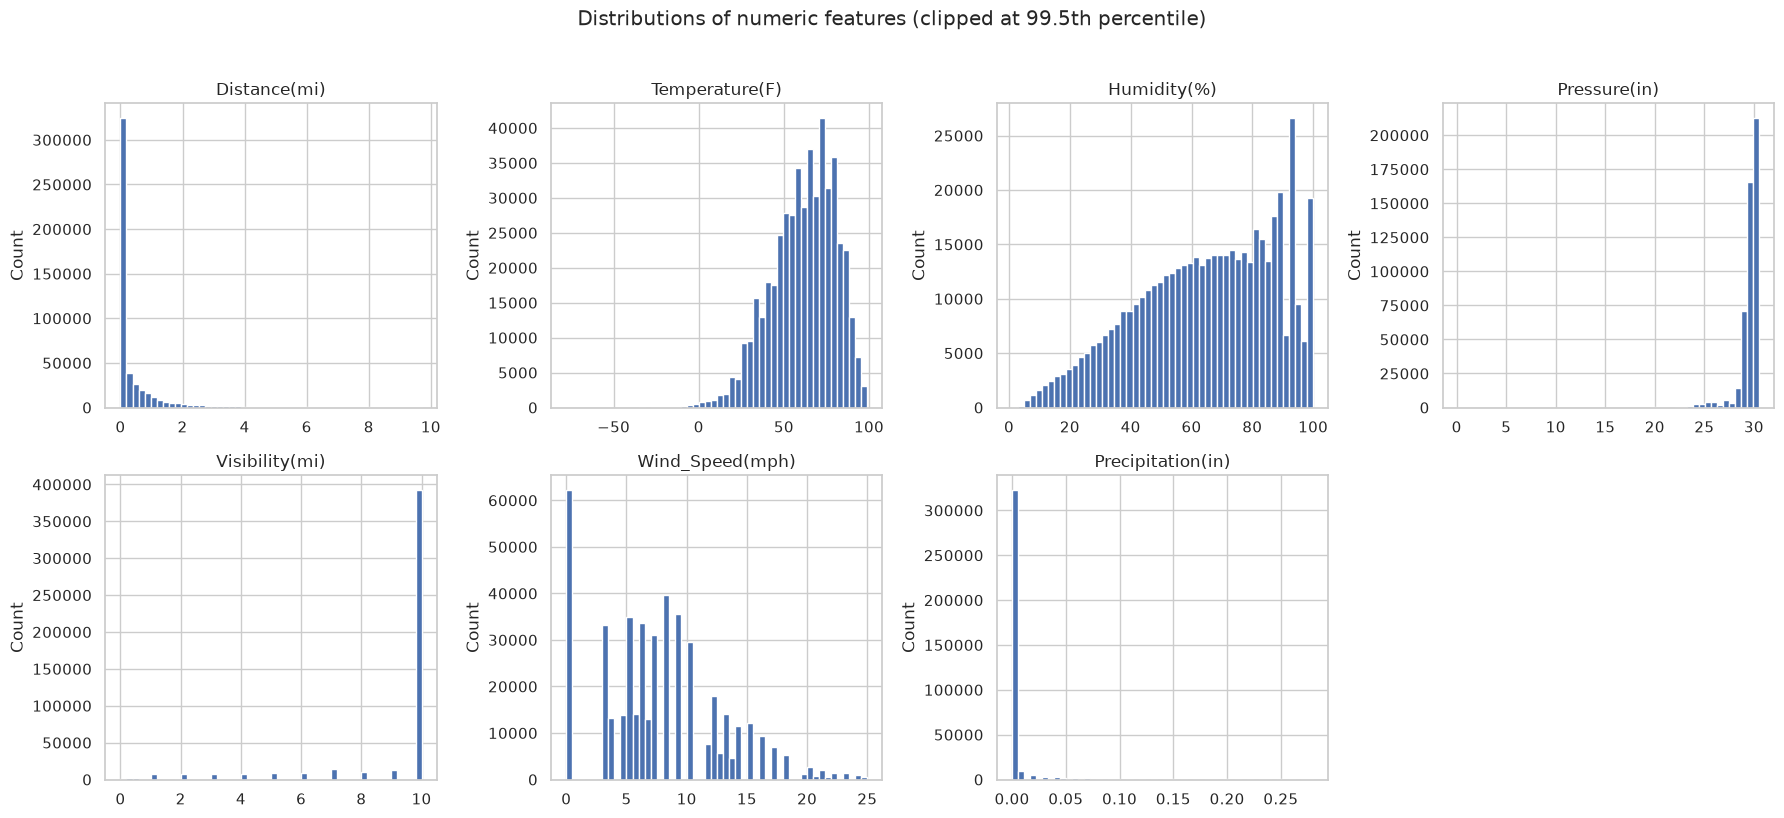

In [38]:
num_cols = ['Distance(mi)', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)',
            'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']
num_cols = [c for c in num_cols if c in df.columns]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    data = df[col].dropna()
    # clip extreme outliers at the 99.5th percentile so the shape is visible
    data = data[data <= data.quantile(0.995)]
    ax.hist(data, bins=50, edgecolor='white')
    ax.set_title(col)
    ax.set_ylabel('Count')
for ax in axes.ravel()[len(num_cols):]:
    ax.axis('off')
plt.suptitle('Distributions of numeric features (clipped at 99.5th percentile)', y=1.02)
plt.tight_layout()
plt.show()

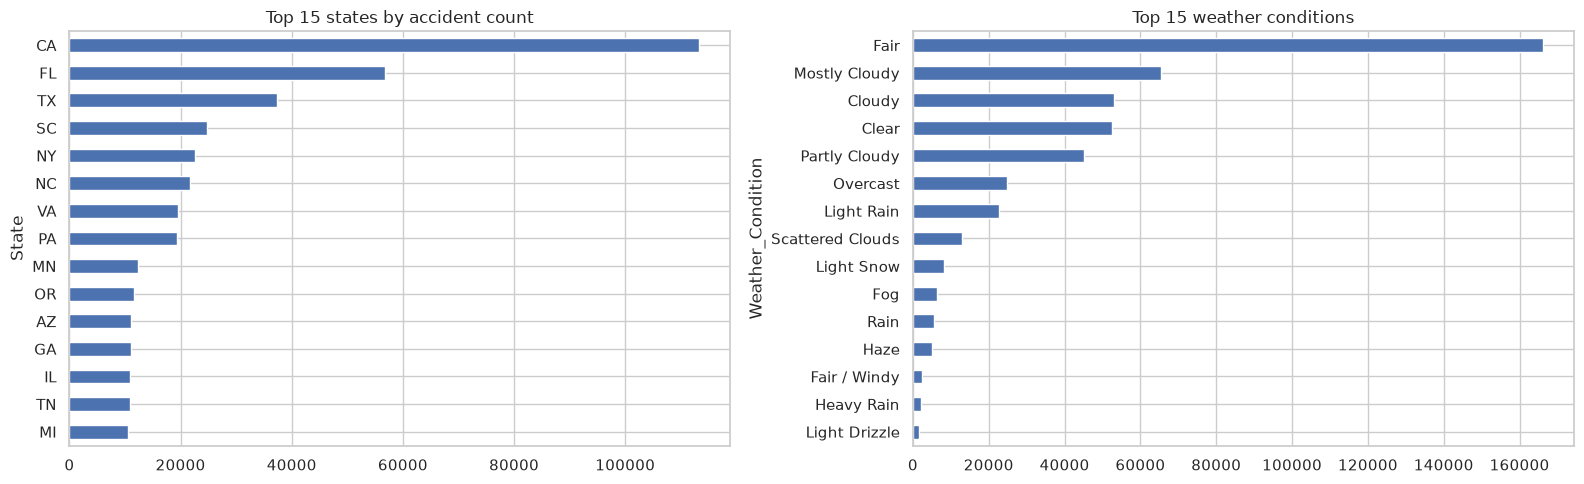

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

df['State'].value_counts().head(15).plot(kind='barh', ax=axes[0])
axes[0].invert_yaxis()
axes[0].set_title('Top 15 states by accident count')

df['Weather_Condition'].value_counts().head(15).plot(kind='barh', ax=axes[1])
axes[1].invert_yaxis()
axes[1].set_title('Top 15 weather conditions')

plt.tight_layout()
plt.show()

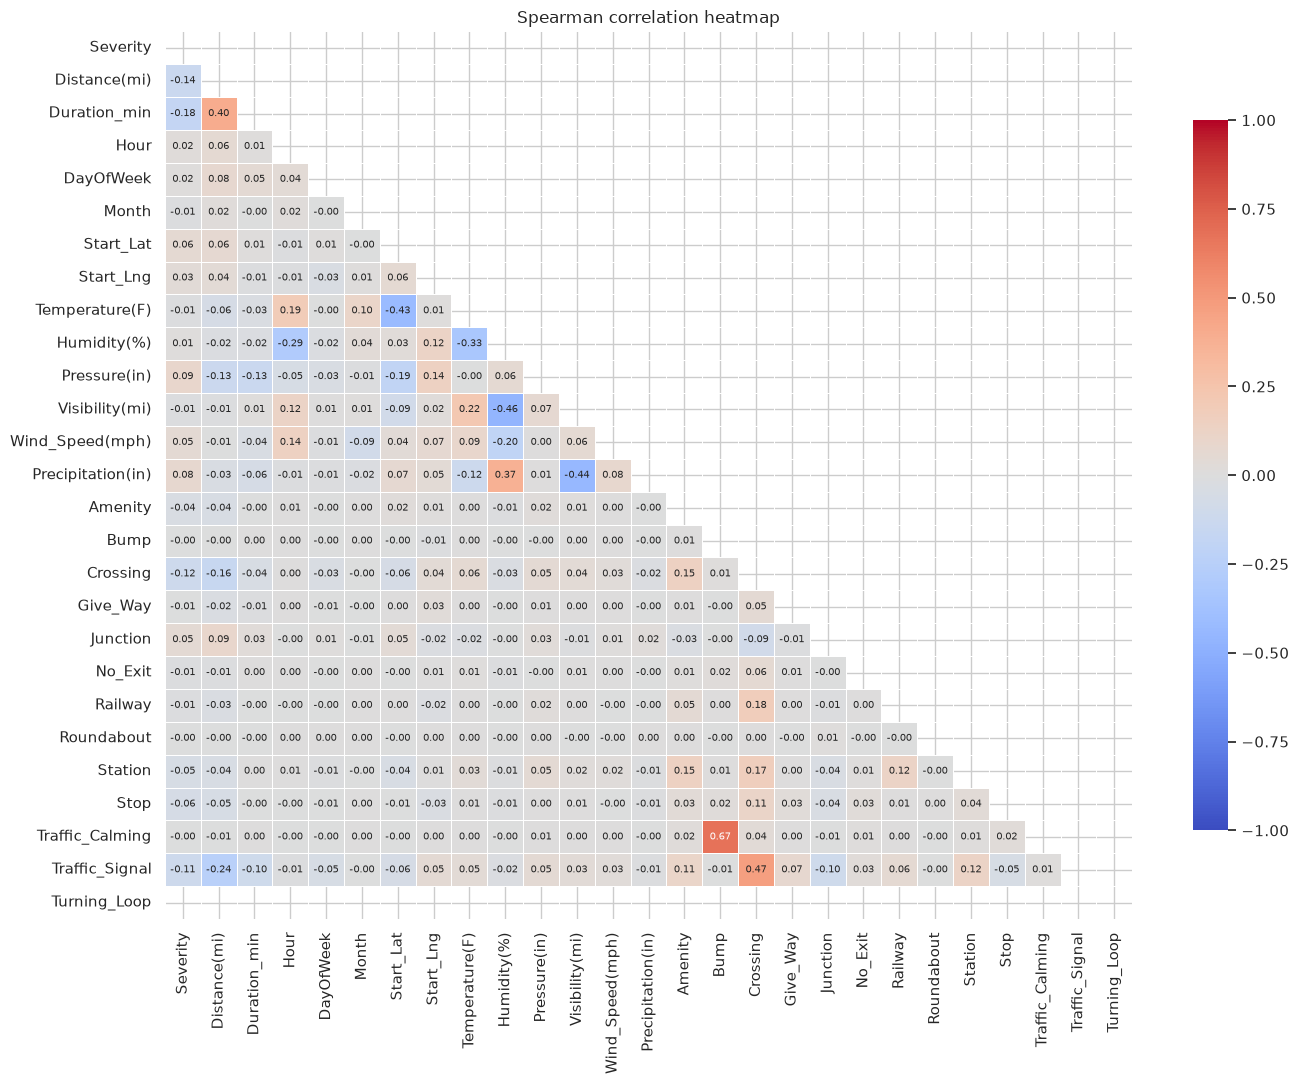

In [40]:
sns.set_theme(style="whitegrid")

bool_cols = df.select_dtypes(include='bool').columns.tolist()

corr_cols = ['Severity', 'Distance(mi)', 'Duration_min', 'Hour', 'DayOfWeek', 'Month',
             'Start_Lat', 'Start_Lng', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)',
             'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']
corr_cols = [c for c in corr_cols if c in df.columns] + bool_cols

corr_df = df[corr_cols].copy()
corr_df[bool_cols] = corr_df[bool_cols].astype(int)

corr = corr_df.corr(method='spearman')   # Spearman handles skew/outliers better than Pearson

mask = np.triu(np.ones_like(corr, dtype=bool))   # hide the redundant upper triangle

plt.figure(figsize=(14, 11))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 7},
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Spearman correlation heatmap')
plt.tight_layout()
plt.show()